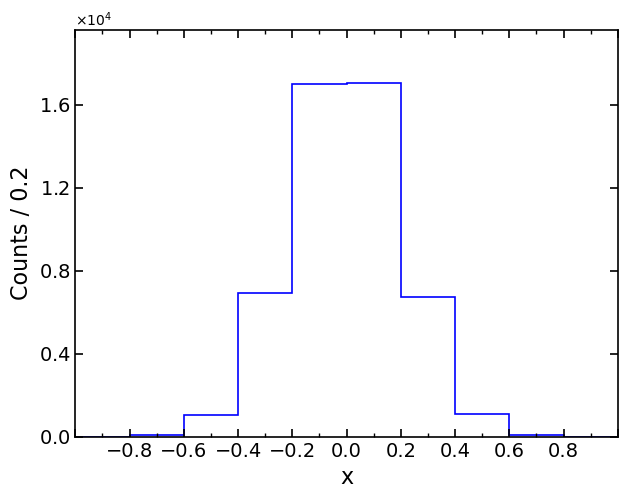

In [1]:
# 功能：三个单元格分别绘制 50000 个高斯样本的直方图、下降指数和上升指数。
# 方法：NumPy 生成样本并分箱或计算指数函数，Matplotlib 绘制独立的 4:3 绘图区。
# 注意事项：依赖 NumPy、Matplotlib；各单元格可独立运行，只显示图形，不保存文件。
# 第一格：横轴 [-1, 1]、bin 宽 0.2；均值与标准差可调，范围外样本不计入可见 bin。
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator, MaxNLocator, MultipleLocator

entries = 50000
mean, sigma = 0.0, 0.2
x_min, x_max = -1.0, 1.0
bin_width = 0.2
frame_aspect = 3.0 / 4.0  # 绘图区高 / 宽，可在此调整。
rng = np.random.default_rng(20261026)
data = rng.normal(loc=mean, scale=sigma, size=entries)
edges = np.linspace(x_min, x_max, round((x_max - x_min) / bin_width) + 1)
counts, edges = np.histogram(data, bins=edges)
actual_bin_width = edges[1] - edges[0]

fig, ax = plt.subplots(figsize=(6.4, 5.2))
ax.stairs(counts, edges, color="blue", linewidth=1.2)
ax.set_box_aspect(frame_aspect)
ax.set_xlim(x_min, x_max)
ax.set_ylim(0, 1.15 * counts.max())
ax.set_xlabel("x", loc="center", fontsize=16)
ax.set_ylabel(f"Counts / {actual_bin_width:g}", loc="center", fontsize=16)
ax.xaxis.set_major_locator(MultipleLocator(bin_width))
ax.xaxis.set_minor_locator(AutoMinorLocator(2))
ax.yaxis.set_major_locator(MaxNLocator(nbins=5, integer=True))
ax.tick_params(axis="both", which="major", direction="in", top=True,
               right=True, length=6, width=1.2, labelsize=14)
ax.tick_params(axis="both", which="minor", direction="in", top=True,
               right=True, length=3, width=1.0)
for spine in ax.spines.values():
    spine.set_linewidth(1.2)
ax.grid(False)

# 只依据最终显示范围内的非零 Y 主刻度判断科学计数法。
y_ticks = ax.get_yticks()
y_ticks = y_ticks[(y_ticks >= ax.get_ylim()[0]) & (y_ticks <= ax.get_ylim()[1])]
nonzero_ticks = np.abs(y_ticks[y_ticks != 0])
if np.any((nonzero_ticks > 1000) | (nonzero_ticks < 0.001)):
    exponent = int(np.floor(np.log10(nonzero_ticks.max())))
    ax.ticklabel_format(axis="y", style="sci", scilimits=(exponent, exponent),
                        useMathText=True, useOffset=False)
fig.tight_layout(pad=0.6)
fig.canvas.draw()
visible_ticks = [tick for tick in ax.xaxis.get_major_ticks()
                 if x_min - 1e-10 <= tick.get_loc() <= x_max + 1e-10]
for tick in (visible_ticks[0], visible_ticks[-1]):
    tick.label1.set_visible(False)
plt.show()


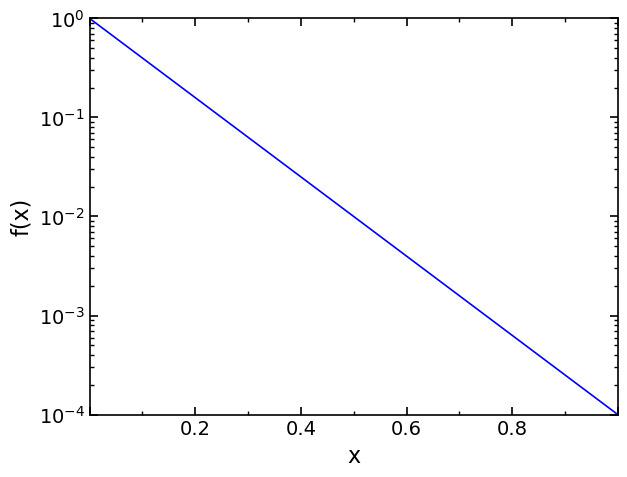

In [1]:
# 功能：绘制下降的指数函数，纵轴范围为 10e-5 到 10e-1。
# 方法：NumPy 在 [0, 1] 上计算指数函数，Matplotlib 使用线性横轴、以 10 为底的对数纵轴和 4:3 绘图区。
# 注意事项：本格可独立运行；10eN 按 Python 数值含义为 10 × 10**N；只显示，不保存文件。
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import (
    AutoMinorLocator, MultipleLocator, LogLocator, LogFormatterMathtext, NullFormatter,
)

x_min, x_max = 0.0, 1.0
y_min, y_max = 10e-5, 10e-1
frame_aspect = 3.0 / 4.0  # 绘图区高 / 宽，可在此调整。
x = np.linspace(x_min, x_max, 500)
t = (x - x_min) / (x_max - x_min)
y = y_max * np.exp(-np.log(y_max / y_min) * t)

fig, ax = plt.subplots(figsize=(6.4, 5.2))
ax.plot(x, y, color="blue", linestyle="-", linewidth=1.2)
ax.set_box_aspect(frame_aspect)
ax.set_xlim(x_min, x_max)
ax.set_yscale("log")
ax.set_ylim(y_min, y_max)
ax.set_xlabel("x", loc="center", fontsize=16)
ax.set_ylabel("f(x)", loc="center", fontsize=16)
ax.xaxis.set_major_locator(MultipleLocator(0.2))
ax.xaxis.set_minor_locator(AutoMinorLocator(2))
# 对数轴：每个数量级显示主刻度，2–9 倍处仅显示次刻度线。
ax.yaxis.set_major_locator(LogLocator(base=10))
ax.yaxis.set_major_formatter(LogFormatterMathtext(base=10))
ax.yaxis.set_minor_locator(LogLocator(base=10, subs=range(2, 10)))
ax.yaxis.set_minor_formatter(NullFormatter())
ax.tick_params(axis="both", which="major", direction="in", top=True,
               right=True, length=6, width=1.2, labelsize=14)
ax.tick_params(axis="both", which="minor", direction="in", top=True,
               right=True, length=3, width=1.0)
for spine in ax.spines.values():
    spine.set_linewidth(1.2)
ax.grid(False)

fig.tight_layout(pad=0.6)
fig.canvas.draw()
visible_ticks = [tick for tick in ax.xaxis.get_major_ticks()
                 if x_min - 1e-10 <= tick.get_loc() <= x_max + 1e-10]
for tick in (visible_ticks[0], visible_ticks[-1]):
    tick.label1.set_visible(False)
plt.show()


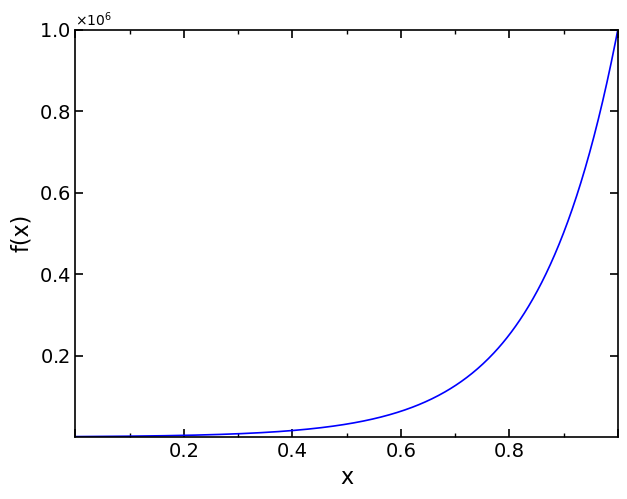

In [2]:
# 功能：绘制上升的指数函数，纵轴范围为 10e2 到 10e5。
# 方法：NumPy 在 [0, 1] 上计算指数函数，Matplotlib 使用线性坐标与 4:3 绘图区。
# 注意事项：本格可独立运行；10eN 按 Python 数值含义为 10 × 10**N；只显示，不保存文件。
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator, MaxNLocator, MultipleLocator

x_min, x_max = 0.0, 1.0
y_min, y_max = 10e2, 10e5
frame_aspect = 3.0 / 4.0  # 绘图区高 / 宽，可在此调整。
x = np.linspace(x_min, x_max, 500)
t = (x - x_min) / (x_max - x_min)
y = y_min * np.exp(np.log(y_max / y_min) * t)

fig, ax = plt.subplots(figsize=(6.4, 5.2))
ax.plot(x, y, color="blue", linestyle="-", linewidth=1.2)
ax.set_box_aspect(frame_aspect)
ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)
ax.set_xlabel("x", loc="center", fontsize=16)
ax.set_ylabel("f(x)", loc="center", fontsize=16)
ax.xaxis.set_major_locator(MultipleLocator(0.2))
ax.xaxis.set_minor_locator(AutoMinorLocator(2))
ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
ax.tick_params(axis="both", which="major", direction="in", top=True,
               right=True, length=6, width=1.2, labelsize=14)
ax.tick_params(axis="both", which="minor", direction="in", top=True,
               right=True, length=3, width=1.0)
for spine in ax.spines.values():
    spine.set_linewidth(1.2)
ax.grid(False)

# 只依据最终显示范围内的非零 Y 主刻度判断科学计数法。
y_ticks = ax.get_yticks()
y_ticks = y_ticks[(y_ticks >= y_min) & (y_ticks <= y_max)]
nonzero_ticks = np.abs(y_ticks[y_ticks != 0])
if np.any((nonzero_ticks > 1000) | (nonzero_ticks < 0.001)):
    exponent = int(np.floor(np.log10(nonzero_ticks.max())))
    ax.ticklabel_format(axis="y", style="sci", scilimits=(exponent, exponent),
                        useMathText=True, useOffset=False)
fig.tight_layout(pad=0.6)
fig.canvas.draw()
visible_ticks = [tick for tick in ax.xaxis.get_major_ticks()
                 if x_min - 1e-10 <= tick.get_loc() <= x_max + 1e-10]
for tick in (visible_ticks[0], visible_ticks[-1]):
    tick.label1.set_visible(False)
plt.show()
